In [11]:
import numpy as np
from proflib import load_profdata
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from pathlib import Path
import re

In [12]:
plt.rcParams.update({
    # --- 图尺寸 ---
    "figure.figsize": (1.6, 1.6),  # 每张图大小，可根据内容微调
    "figure.dpi": 170,

    # --- 字体 ---
    "font.family": "serif",
    "font.serif": ["Times New Roman"],
    "mathtext.fontset": "cm",   # 数学字体与 LaTeX 一致
    "font.size": 7,             # IEEE/ACM 通常 7pt；Nature 通常 8pt
    "axes.labelsize": 7,
    "axes.titlesize": 7,
    "legend.fontsize": 6,
    "xtick.labelsize": 6,
    "ytick.labelsize": 6,

    # --- 线条和标记 ---
    "lines.linewidth": 0.8,
    "lines.markersize": 3,
    "axes.linewidth": 0.5,  # 坐标轴线条
    "grid.linewidth": 0.3,

    # --- 图例 ---
    "legend.frameon": False,
    "legend.handlelength": 1.5,

    # --- 刻度 ---
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.major.size": 2,
    "ytick.major.size": 2,
    "xtick.minor.size": 1.2,
    "ytick.minor.size": 1.2,
    "xtick.major.width": 0.4,
    "ytick.major.width": 0.4,

    # --- 版面 ---
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.01,

    "image.cmap": "cividis",      # 连续型默认
    "axes.prop_cycle": plt.cycler("color", plt.cm.tab10.colors),  # 折线色
})

# Overall

In [13]:
all_data = []

# files = (
#     sorted(Path('exp-data-v1/').glob('data/*/prof.*/linux.bin.out'))
#     + sorted(Path('exp-data-v2/').glob('data/*/prof.repcut/linux.bin.out'))
#     # sorted(Path('baseline/vlt/build/').glob('*/prof.*/linux.bin.out'))
# )

files = (
    sorted(Path('build').glob('*/prof.*/coremark-2.bin.out'))
    + sorted(Path('baseline/gsim/').glob('build/*/prof.gsim/coremark-2.bin.out'))
    # + sorted(Path('baseline/vlt/').glob('build/*/prof.vlt/coremark-2.bin.out'))
    + sorted(Path('../repcut-eval').glob('build/*/prof.repcut/coremark-2.out'))
    # + sorted(Path('exp-data-v1/').glob('data/*/prof.gsim/linux.bin.out'))
    # + sorted(Path('exp-data-v1/').glob('data/*/prof.vlt/linux.bin.out'))
    # + sorted(Path('exp-data-v2/').glob('data/*/prof.repcut/linux.bin.out'))
)

design_canon = {
    'boom_l': 'LargeBoom',
    'boom_m': 'MediumBoom',
    'rocket_m': 'Rocket',
}

for file in files:
    data = file.with_suffix('.out').read_text()
    items = re.findall(r'cycle=(\d+), last_freq=([0-9.]+) kHz, freq=([0-9.]+) kHz', data)
    print(file)
    total_cycles, _, freq = items[-1]
    total_cycles = int(total_cycles)
    freq = float(freq)
    design = file.parent.parent.stem
    sp = design.rfind('_')
    design_base = design[:sp]
    design_cnt = int(design[sp+1:])
    threads = int(file.parent.parent.suffix[2:] or 1)
    kind = file.parent.suffix[1:]
    data = {
        'design': design_canon[design_base],
        'cores': design_cnt,
        'design_full': design,
        'threads': threads,
        'total_cycles': total_cycles,
        'freq': freq,
        'kind': kind,
    }
    all_data.append(data)
df = pd.DataFrame(all_data)
df

baseline/gsim/build/boom_l_1/prof.gsim/coremark-2.bin.out
baseline/gsim/build/boom_l_2/prof.gsim/coremark-2.bin.out
baseline/gsim/build/boom_l_4/prof.gsim/coremark-2.bin.out
baseline/gsim/build/boom_m_1/prof.gsim/coremark-2.bin.out
baseline/gsim/build/boom_m_2/prof.gsim/coremark-2.bin.out
baseline/gsim/build/boom_m_4/prof.gsim/coremark-2.bin.out
baseline/gsim/build/rocket_m_1/prof.gsim/coremark-2.bin.out
baseline/gsim/build/rocket_m_2/prof.gsim/coremark-2.bin.out
baseline/gsim/build/rocket_m_4/prof.gsim/coremark-2.bin.out
../repcut-eval/build/boom_l_1.T1/prof.repcut/coremark-2.out
../repcut-eval/build/boom_l_1.T10/prof.repcut/coremark-2.out
../repcut-eval/build/boom_l_1.T12/prof.repcut/coremark-2.out
../repcut-eval/build/boom_l_1.T14/prof.repcut/coremark-2.out
../repcut-eval/build/boom_l_1.T16/prof.repcut/coremark-2.out
../repcut-eval/build/boom_l_1.T2/prof.repcut/coremark-2.out
../repcut-eval/build/boom_l_1.T20/prof.repcut/coremark-2.out
../repcut-eval/build/boom_l_1.T24/prof.repcut/c

,design,cores,design_full,threads,total_cycles,freq,kind
0,LargeBoom,1,boom_l_1,1,1500000,81.7857,gsim
1,LargeBoom,2,boom_l_2,1,1500000,46.7380,gsim
2,LargeBoom,4,boom_l_4,1,1500000,16.3354,gsim
3,MediumBoom,1,boom_m_1,1,1500000,129.2380,gsim
4,MediumBoom,2,boom_m_2,1,1500000,81.9663,gsim
...,...,...,...,...,...,...,...
148,Rocket,4,rocket_m_4,4,1000000,107.8980,repcut
149,Rocket,4,rocket_m_4,5,1000000,113.7280,repcut
150,Rocket,4,rocket_m_4,6,1000000,121.7790,repcut
151,Rocket,4,rocket_m_4,7,1000000,135.5970,repcut


In [14]:
piv = df.groupby(['design', 'cores', 'kind']).agg({'freq': 'max'}).unstack()
piv.style.format('{:.1f}')

In [15]:
import scipy.stats as stats

In [16]:
stats.mstats.gmean(piv[('freq', 'pgo')] / piv[('freq', 'ref')])

KeyError: ('freq', 'pgo')

In [ ]:
for col in piv['freq']:
    piv[('speedup', col)] = piv[('freq', col)] / piv[('freq', 'vlt')]

In [17]:
order = ['pgo', 'ref', 'repcut', 'gsim', 'vlt']
columns = [('freq', x) for x in order] + [('speedup', x) for x in order]
piv = piv[columns]

styled = (piv.style
    .format('{:.1f}', subset='freq')
    .format('{:.2f}', subset='speedup')
    .highlight_max(subset='freq', props='font-weight:bold', axis=1)
    .highlight_max(subset='speedup', props='font-weight:bold', axis=1)
)
styled

KeyError: "[('freq', 'pgo'), ('freq', 'ref'), ('freq', 'vlt'), ('speedup', 'pgo'), ('speedup', 'ref'), ('speedup', 'repcut'), ('speedup', 'gsim'), ('speedup', 'vlt')] not in index"

In [135]:
print(styled.to_latex(convert_css=True))

\begin{tabular}{llrrrrrrrrrr}
 &  & \multicolumn{5}{r}{freq} & \multicolumn{5}{r}{speedup} \\
 & kind & pgo & ref & repcut & gsim & vlt & pgo & ref & repcut & gsim & vlt \\
design & cores &  &  &  &  &  &  &  &  &  &  \\
\multirow[c]{3}{*}{LargeBoom} & 1 & nan & nan & \bfseries 152.7 & 66.9 & 43.5 & nan & nan & \bfseries 3.51 & 1.54 & 1.00 \\
 & 2 & nan & nan & \bfseries 155.2 & 42.2 & 26.6 & nan & nan & \bfseries 5.83 & 1.58 & 1.00 \\
 & 4 & nan & nan & \bfseries 156.5 & 14.9 & 19.8 & nan & nan & \bfseries 7.89 & 0.75 & 1.00 \\
\multirow[c]{3}{*}{MediumBoom} & 1 & 206.4 & \bfseries 247.6 & 182.6 & 102.5 & 47.0 & 4.39 & \bfseries 5.26 & 3.88 & 2.18 & 1.00 \\
 & 2 & nan & nan & \bfseries 169.8 & 70.9 & 38.2 & nan & nan & \bfseries 4.45 & 1.86 & 1.00 \\
 & 4 & nan & nan & \bfseries 125.5 & 39.4 & 25.8 & nan & nan & \bfseries 4.86 & 1.53 & 1.00 \\
\multirow[c]{3}{*}{Rocket} & 1 & \bfseries 388.3 & 386.5 & 281.9 & 263.3 & 99.3 & \bfseries 3.91 & 3.89 & 2.84 & 2.65 & 1.00 \\
 & 2 & nan & na

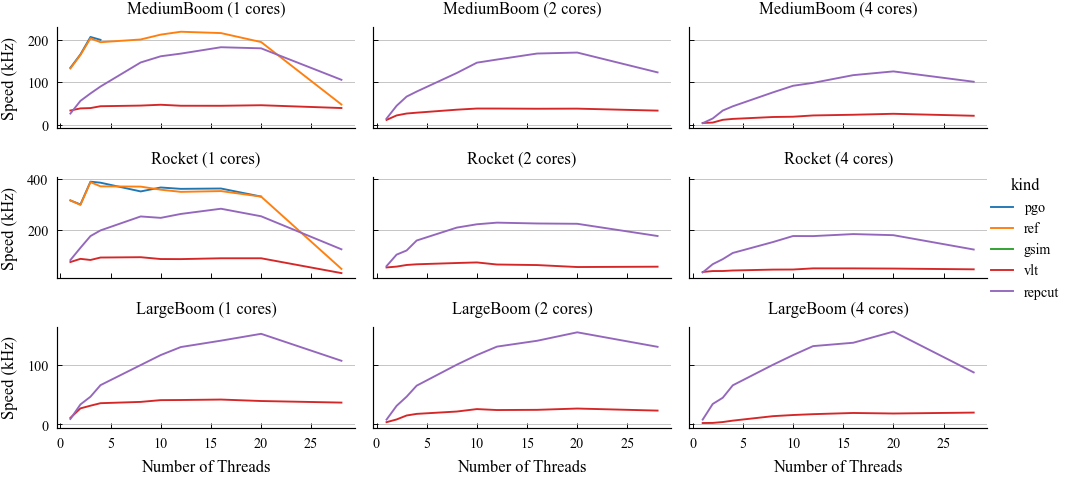

In [136]:
facet = sns.relplot(
    df.query('threads < 32 and threads != 5 and threads != 6 and threads != 7 and threads != 14 and threads != 24'),
    kind='line',
    x='threads',
    y='freq', 
    hue='kind',
    col='cores',
    row='design',
    height=1,
    aspect=2,
    facet_kws=dict(
        sharey='row',
    )
)
facet.set_titles('{row_name} ({col_name} cores)')
facet.set_ylabels('Speed (kHz)')
facet.set_xlabels('Number of Threads')
for ax in facet.axes.flatten():
    ax.grid(axis='y')
sns.despine()
plt.savefig('scaling-curve.pdf')

# Case Study

In [70]:
import numpy as np
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from proflib import load_profdata

In [71]:
sync_time_df = pd.read_csv('scratch/thread-sync-cost.csv', sep=r'\s+')
sync_time = np.zeros((33,), dtype=np.int32)
sync_time[sync_time_df.threads] = sync_time_df.rdtsc / 2
sync_time

array([   0,   74,  735,  875, 1040, 1185, 1353, 1516, 1661, 1805, 1959,
       2105, 2254, 2426, 2594, 2765, 2930, 3109, 3281, 3440, 3605, 3780,
       3941, 4108, 4286, 4480, 4605, 4713, 4821, 4977, 5085, 5187, 5301],
      dtype=int32)

In [72]:
def convert_data(data):
    stime = sync_time[len(data.threads)]
    step_elapsed = data.rdtsc_avg()
    wait_time = step_elapsed[:, [1, 3]].sum(axis=-1, keepdims=True)
    idle_time = wait_time - stime
    neg = np.where(idle_time < 0, idle_time, 0).min()
    stime += neg
    step_pivot = np.concatenate([
        step_elapsed[:, [2]].sum(axis=-1, keepdims=True),
        wait_time - stime,
        np.full((step_elapsed.shape[0], 1), fill_value=stime, dtype=step_elapsed.dtype),
        step_elapsed[:, [0, 4]].sum(axis=-1, keepdims=True),
    ], axis=-1)
    step_names = ['step', 'wait', 'barrier', 'comm']
    return step_pivot, step_names

In [74]:
data_ref = load_profdata('build/boom_m_1.T4/prof.ref/coremark.bin')
step_ticks_ref, step_names = convert_data(data_ref)


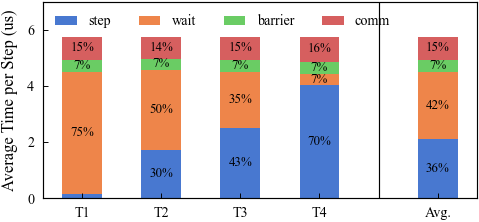

In [80]:
plt.figure(figsize=(3.3, 1.5))
argidx = np.argsort(step_ticks_ref[:, 0])
step_mean = step_ticks_ref[argidx] / 2.5 / 1000
handles = plot_stack_bar(step_mean, colors=cmap, include_avg=True)
plt.ylabel('Average Time per Step (us)')
plt.legend(handles, step_names, loc='upper left', ncols=4)
plt.ylim([0, 7])
plt.savefig('thread-breakdown-boom-l-t12.ref.pdf')

In [9]:
data_pgo = load_profdata('build/boom_m_1.T12/prof.pgo/linux.bin')
step_ticks_pgo, step_names = convert_data(data_pgo)

NameError: name 'convert_data' is not defined

In [10]:
def plot_stack_bar(data, include_avg=False, colors=None):
    stack = np.cumsum(data, axis=1)
    xlabels = [f'T{i+1}' for i in range(data.shape[0])]
    x = np.arange(data.shape[0])
    if include_avg:
        avg = data.mean(axis=0)
        data = np.concatenate([data, avg[None]], axis=0)
        xsep = x[-1] + 1.5 / 2
        x = np.concatenate([x, [x[-1] + 1.5]])
        plt.axvline(xsep, color='k', lw=0.5)
        xlabels.append('Avg.')
    stack = np.cumsum(data, axis=1)
    data_pct = data / data.sum(axis=1, keepdims=True)
    handles = []
    for i in range(data.shape[1]):
        bottom = np.zeros(data.shape[0]) if i == 0 else stack[:, i-1]
        color = colors[i] if colors else None
        h = plt.bar(x, data[:, i], width=0.5, bottom=bottom, color=color)
        for j in range(data.shape[0]):
            if data_pct[:, i][j] < 0.05:
                continue
            plt.text(
                x[j],
                bottom[j] + data[:, i][j] / 2,
                f'{data_pct[:, i][j]:.0%}',
                ha='center',
                va='center',
                color='k',
                fontsize=5.5,
            )
        handles.append(h)
    plt.xticks(x, xlabels)
    return handles

In [78]:
cmap = sns.color_palette('grey', 4)
cmap

[(0.2, 0.2, 0.2), (0.4, 0.4, 0.4), (0.6, 0.6, 0.6), (0.8, 0.8, 0.8)]

In [79]:
cmap = sns.color_palette("muted", 10)

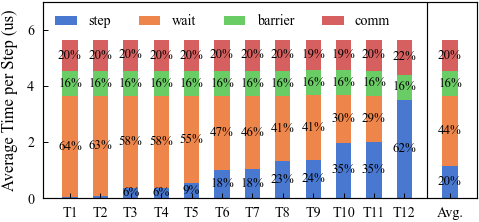

In [57]:
plt.figure(figsize=(3.3, 1.5))
argidx = np.argsort(step_ticks_ref[:, 0])
step_mean = step_ticks_ref[argidx] / 2.5 / 1000
handles = plot_stack_bar(step_mean, colors=cmap, include_avg=True)
plt.ylabel('Average Time per Step (us)')
plt.legend(handles, step_names, loc='upper left', ncols=4)
plt.ylim([0, 7])
plt.savefig('thread-breakdown-boom-l-t12.ref.pdf')

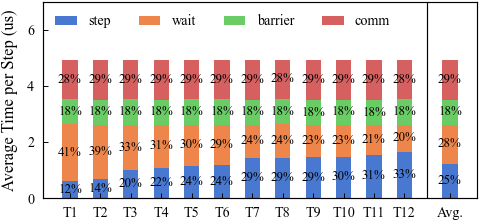

In [58]:
plt.figure(figsize=(3.3, 1.5))
argidx = np.argsort(step_ticks_pgo[:, 0])
step_mean = step_ticks_pgo[argidx] / 2.5 / 1000
cmap = sns.color_palette("muted", 10)
handles = plot_stack_bar(step_mean, colors=cmap, include_avg=True)
plt.ylabel('Average Time per Step (us)')
plt.ylim([0, 7])
plt.legend(handles, step_names, loc='upper left', ncols=4)
plt.savefig('thread-breakdown-boom-l-t12.pgo.pdf')

# Sampling Method

In [59]:
ground_truth = np.load('prof-method-stat/ground-truth.npy')
minhash_method = np.load('prof-method-stat/minhash-method.npy') ** 0.7
binsample_method = np.load('prof-method-stat/binsample-method.npy')

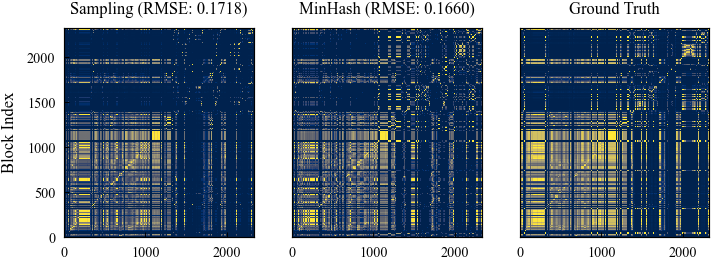

In [60]:
# plt.figure(figsize=(1.6*3, 1.6))
fig, ax = plt.subplots(1, 3, figsize=(3*1.6+0.1, 1.6), squeeze=True)
ax[0].pcolormesh(binsample_method, rasterized=True)
rmse = np.sqrt(((binsample_method - ground_truth) ** 2).mean())
ax[0].set_title(f'Sampling (RMSE: {rmse:.4f})')
ax[1].pcolormesh(minhash_method, rasterized=True)
ax[1].set_yticks([])
rmse = np.sqrt(((minhash_method - ground_truth) ** 2).mean())
ax[1].set_title(f'MinHash (RMSE: {rmse:.4f})')
ax[2].pcolormesh(ground_truth, rasterized=True)
ax[2].set_yticks([])
ax[2].set_title(f'Ground Truth')
ax[0].set_ylabel('Block Index')
# ax[1].set_xlabel('Block Index')
plt.savefig('prof-method-stat.pdf')